<a href="https://colab.research.google.com/github/KenNicholas/komparatif-genai/blob/main/komparatif_genai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Setup dan Import Awal


In [1]:
# import
import torch, numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

print('pytorch:', torch.__version__)
print('gpu:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu')

pytorch: 2.14.1+cu130
gpu: Tesla T4


## Load dataset FashionMNIST

In [2]:
tf = transforms.Compose([transforms.ToTensor()])
train_full = datasets.FashionMNIST(root='./data', train=True, download=True, transform=tf)
test_full = datasets.FashionMNIST(root='./data', train=False, download=True, transform=tf)

print('Train: ', len(train_full))
print('Test: ', len(test_full))

Train:  60000
Test:  10000


In [3]:
x = np.concatenate([
    np.stack([train_full[i][0].numpy() for i in range(len(train_full))]),
    np.stack([test_full[i][0].numpy()  for i in range(len(test_full))])
], axis=0)

y = np.concatenate([
    np.array([train_full[i][1] for i in range(len(train_full))]),
    np.array([test_full[i][1]  for i in range(len(test_full))])
], axis=0)

print('Digabung: ')
print('Total: ', len(x))
print('Classes: ', train_full.classes)

Digabung: 
Total:  70000
Classes:  ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


## EDA

In [4]:
from collections import Counter

counts = Counter(y.tolist())

for i in sorted(counts):
  print(f'{i:2d} {train_full.classes[i]:12s} {counts[i]}')

 0 T-shirt/top  7000
 1 Trouser      7000
 2 Pullover     7000
 3 Dress        7000
 4 Coat         7000
 5 Sandal       7000
 6 Shirt        7000
 7 Sneaker      7000
 8 Bag          7000
 9 Ankle boot   7000


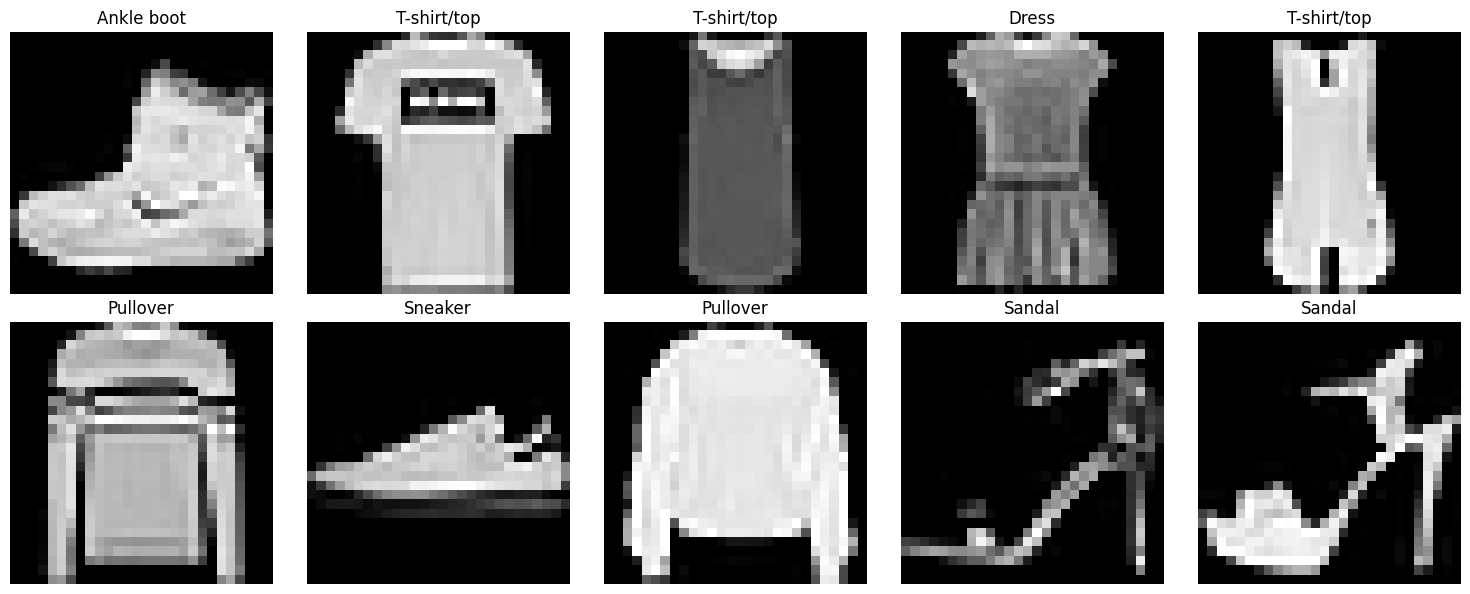

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15,6))

for ax,i in zip(axes.flat, range(10)):
  img, label = train_full[i]
  ax.imshow(img.squeeze(), cmap='gray')
  ax.set_title(train_full.classes[label])
  ax.axis('off')

plt.tight_layout()
plt.show()

## Train test split (80/10/10)

In [6]:
from sklearn.model_selection import train_test_split

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [7]:
train_set = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
val_set = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val))
test_set = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))

print('Train: ', len(train_set))
print('Validation: ', len(val_set))
print('Test: ', len(test_set))

Train:  56000
Validation:  7000
Test:  7000


## Dataloader

In [8]:
train = DataLoader(train_set, batch_size=128, shuffle=True)
val = DataLoader(val_set,   batch_size=128, shuffle=False)
test = DataLoader(test_set,  batch_size=128, shuffle=False)

## simpan utils.py dan data.py

In [9]:
!mkdir -p src

In [10]:
%%writefile src/utils.py
import torch, numpy as np, random, json, os

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def get_device():
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Overwriting src/utils.py


In [11]:
%%writefile src/data.py
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

def get_loaders(batch_size=128, seed=42):
    tf = transforms.Compose([transforms.ToTensor()])
    train_full = datasets.FashionMNIST(root='./data', train=True,  download=True, transform=tf)
    test_full  = datasets.FashionMNIST(root='./data', train=False, download=True, transform=tf)

    x = np.concatenate([
        np.stack([train_full[i][0].numpy() for i in range(len(train_full))]),
        np.stack([test_full[i][0].numpy()  for i in range(len(test_full))])
    ], axis=0)
    y = np.concatenate([
        np.array([train_full[i][1] for i in range(len(train_full))]),
        np.array([test_full[i][1]  for i in range(len(test_full))])
    ], axis=0)

    x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=seed, stratify=y)
    x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=seed, stratify=y_temp)

    train_set = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
    val_set = TensorDataset(torch.from_numpy(x_val), torch.from_numpy(y_val))
    test_set = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))

    return (DataLoader(train_set, batch_size=batch_size, shuffle=True),
            DataLoader(val_set,batch_size=batch_size, shuffle=False),
            DataLoader(test_set,batch_size=batch_size, shuffle=False))

Overwriting src/data.py


# 2. Vanilla AutoEncoder

In [12]:
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class VanillaAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x.flatten(1))
        return self.decoder(z), z

def train_vanilla_ae(epochs=30, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = VanillaAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, _ = model(images)
            loss = F.mse_loss(xr, images.flatten(1))
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, _ = model(images)
                val_loss_sum += F.mse_loss(xr, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

In [13]:
# train 30 epoch
model_ae, hist_ae, sec_ae, best_ep_ae, best_val_ae = train_vanilla_ae()
print('='*25)
print(f'best_ep={best_ep_ae} best_val={best_val_ae:.5f} , sec/epoch={sec_ae:.2f}')

Epoch 01 : train 0.03173 , val 0.01859
Epoch 02 : train 0.01655 , val 0.01499
Epoch 03 : train 0.01390 , val 0.01306
Epoch 04 : train 0.01243 , val 0.01189
Epoch 05 : train 0.01133 , val 0.01102
Epoch 06 : train 0.01058 , val 0.01033
Epoch 07 : train 0.00997 , val 0.00997
Epoch 08 : train 0.00950 , val 0.00953
Epoch 09 : train 0.00910 , val 0.00910
Epoch 10 : train 0.00876 , val 0.00876
Epoch 11 : train 0.00844 , val 0.00849
Epoch 12 : train 0.00818 , val 0.00826
Epoch 13 : train 0.00795 , val 0.00810
Epoch 14 : train 0.00774 , val 0.00783
Epoch 15 : train 0.00756 , val 0.00774
Epoch 16 : train 0.00741 , val 0.00759
Epoch 17 : train 0.00724 , val 0.00742
Epoch 18 : train 0.00711 , val 0.00728
Epoch 19 : train 0.00702 , val 0.00718
Epoch 20 : train 0.00690 , val 0.00708
Epoch 21 : train 0.00680 , val 0.00702
Epoch 22 : train 0.00673 , val 0.00693
Epoch 23 : train 0.00664 , val 0.00684
Epoch 24 : train 0.00657 , val 0.00676
Epoch 25 : train 0.00651 , val 0.00670
Epoch 26 : train 0.00646 

In [14]:
# metrik evaluasi: MSE, PSNR, SSIM, latency GPU, Variance of Laplacian
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from scipy.ndimage import laplace

device = get_device()
_, _, test = get_loaders()
model_ae.eval()
mse_sum = 0
psnr_sum = 0
ssim_sum = 0
lap_sum = 0
n = 0
with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _ = model_ae(images)
        for i in range(images.size(0)):
            asli = images[i,0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28,28).numpy()
            mse_sum  += float(((asli-rekonstruksi)**2).mean())
            psnr_sum += psnr_fn(asli, rekonstruksi, data_range=1.0)
            ssim_sum += ssim_fn(asli, rekonstruksi, data_range=1.0)
            lap_sum  += laplace(asli).var()
            n += 1

mse_ae = mse_sum / n
psnr_ae = psnr_sum / n
ssim_ae = ssim_sum / n
laplacian_ae = lap_sum / n

batch_64 = next(iter(test))[0][:64].to(device)
for _ in range(10):
    model_ae(batch_64)
torch.cuda.synchronize()
start_time = time.time()
for _ in range(50):
    model_ae(batch_64)
torch.cuda.synchronize()
latency_ae = (time.time() - start_time) / 50 * 1000

print('Vanilla AutoEncoder')
print('='*25)
print(f'MSE {mse_ae:.3f}')
print(f'PSNR {psnr_ae:.2f}')
print(f'SSIM {ssim_ae:.3f}')
print(f'Variance of Laplacian: {laplacian_ae:.2f}')
print(f'latency GPU: {latency_ae:.2f}ms')

Vanilla AutoEncoder
MSE 0.006
PSNR 23.02
SSIM 0.828
Variance of Laplacian: 0.16
latency GPU: 0.21ms


In [15]:
# Perbandingan antara Variance of Laplacian: asli dan rekonstruksi
import numpy as np
from scipy.ndimage import laplace

model_ae.eval()
laplacian_real = 0
laplacian_recon = 0
n = 0

with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _ = model_ae(images)
        for i in range(images.size(0)):
            asli = images[i, 0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28, 28).numpy()
            laplacian_real += laplace(asli).var()
            laplacian_recon += laplace(rekonstruksi).var()
            n += 1

laplacian_real = laplacian_real/n
laplacian_reconstruction = laplacian_recon/n

print(f'Laplacian asli : {laplacian_real:.3f}')
print(f'Laplacian rekonstruksi : {laplacian_reconstruction:.3f}')
print(f'Rasio rekonstruksi/asli: {laplacian_reconstruction / laplacian_real:.2f}')

Laplacian asli : 0.164
Laplacian rekonstruksi : 0.082
Rasio rekonstruksi/asli: 0.50


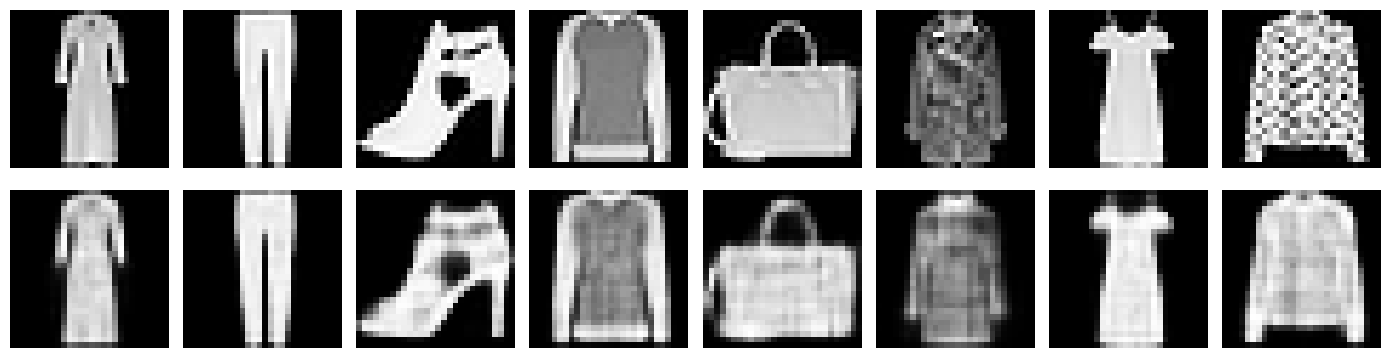

In [16]:
import matplotlib.pyplot as plt
images, _ = next(iter(test));
images = images[:8].to(device)
with torch.no_grad():
  xr, _ = model_ae(images)

fig, ax = plt.subplots(2, 8, figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(images[i,0].cpu(), cmap='gray');
    ax[0,i].axis('off')
    ax[1,i].imshow(xr[i].cpu().reshape(28,28), cmap='gray');
    ax[1,i].axis('off')
plt.tight_layout();
plt.show()

In [17]:
%%writefile src/vanilla_ae.py
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class VanillaAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        z = self.encoder(x.flatten(1))
        return self.decoder(z), z

def train_vanilla_ae(epochs=30, lr=1e-3, batch_size=128, seed=42):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = VanillaAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            reconstruction, _ = model(images)
            loss = F.mse_loss(reconstruction, images.flatten(1))
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                reconstruction, _ = model(images)
                val_loss_sum += F.mse_loss(reconstruction, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'epoch {epoch+1:02d} train {train_loss:.5f} val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

Overwriting src/vanilla_ae.py


## 3. Sparse AutoEncoder

In [27]:
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class SparseAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        h = self.encoder[1](self.encoder[0](x.flatten(1)))
        z = self.encoder[2](h)
        return self.decoder(z), z, h

def train_sparse_ae(epochs=30, lr=1e-3, batch_size=128, seed=42, lam=1e-3):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = SparseAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, _, h = model(images)
            loss = F.mse_loss(xr, images.flatten(1)) + lam * h.abs().mean()
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, _, _ = model(images)
                val_loss_sum += F.mse_loss(xr, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

In [28]:
model_sae, hist_sae, sec_sae, best_ep_sae, best_val_sae = train_sparse_ae()
print('='*25)
print(f'best_ep={best_ep_sae} best_val={best_val_sae:.5f} , sec/epoch={sec_sae:.2f}')

Epoch 01 : train 0.03216 , val 0.01865
Epoch 02 : train 0.01694 , val 0.01509
Epoch 03 : train 0.01437 , val 0.01318
Epoch 04 : train 0.01283 , val 0.01200
Epoch 05 : train 0.01180 , val 0.01130
Epoch 06 : train 0.01104 , val 0.01057
Epoch 07 : train 0.01045 , val 0.01004
Epoch 08 : train 0.00995 , val 0.00959
Epoch 09 : train 0.00955 , val 0.00920
Epoch 10 : train 0.00923 , val 0.00892
Epoch 11 : train 0.00890 , val 0.00865
Epoch 12 : train 0.00864 , val 0.00839
Epoch 13 : train 0.00843 , val 0.00823
Epoch 14 : train 0.00822 , val 0.00807
Epoch 15 : train 0.00805 , val 0.00793
Epoch 16 : train 0.00788 , val 0.00777
Epoch 17 : train 0.00773 , val 0.00758
Epoch 18 : train 0.00759 , val 0.00750
Epoch 19 : train 0.00748 , val 0.00735
Epoch 20 : train 0.00737 , val 0.00729
Epoch 21 : train 0.00727 , val 0.00718
Epoch 22 : train 0.00717 , val 0.00712
Epoch 23 : train 0.00710 , val 0.00703
Epoch 24 : train 0.00702 , val 0.00694
Epoch 25 : train 0.00695 , val 0.00692
Epoch 26 : train 0.00689 

In [29]:
# metrik evaluasi: MSE, PSNR, SSIM, latency GPU, Variance of Laplacian
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from scipy.ndimage import laplace

device = get_device()
_, _, test = get_loaders()
model_sae.eval()
mse_sum = 0
psnr_sum = 0
ssim_sum = 0
lap_sum = 0
n = 0
with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _, _ = model_sae(images)
        for i in range(images.size(0)):
            asli = images[i,0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28,28).numpy()
            mse_sum  += float(((asli-rekonstruksi)**2).mean())
            psnr_sum += psnr_fn(asli, rekonstruksi, data_range=1.0)
            ssim_sum += ssim_fn(asli, rekonstruksi, data_range=1.0)
            lap_sum  += laplace(asli).var()
            n += 1

mse_sae = mse_sum / n
psnr_sae = psnr_sum / n
ssim_sae = ssim_sum / n
laplacian_sae = lap_sum / n

batch_64 = next(iter(test))[0][:64].to(device)
for _ in range(10):
    model_sae(batch_64)
torch.cuda.synchronize()
waktu_mulai = time.time()
for _ in range(50):
    model_sae(batch_64)
torch.cuda.synchronize()
latency_sae = (time.time() - waktu_mulai) / 50 * 1000

print('SPARSE ENCODER')
print('='*25)
print(f'MSE {mse_sae:.3f}')
print(f'PSNR {psnr_sae:.2f}')
print(f'SSIM {ssim_sae:.3f}')
print(f'Variance of Laplacian: {laplacian_sae:.2f}')
print(f'latency GPU: {latency_sae:.2f}ms')

SPARSE ENCODER
MSE 0.007
PSNR 22.94
SSIM 0.827
Variance of Laplacian: 0.16
latency GPU: 0.30ms


In [30]:
# Perbandingan antara Variance of Laplacian: asli dan rekonstruksi
import numpy as np
from scipy.ndimage import laplace

model_ae.eval()
laplacian_real = 0
laplacian_recon = 0
n = 0

with torch.no_grad():
    for images, _ in test:
        images = images.to(device)
        xr, _ = model_ae(images)
        for i in range(images.size(0)):
            asli = images[i, 0].cpu().numpy()
            rekonstruksi = xr[i].cpu().reshape(28, 28).numpy()
            laplacian_real += laplace(asli).var()
            laplacian_recon += laplace(rekonstruksi).var()
            n += 1

laplacian_real = laplacian_real/n
laplacian_reconstruction = laplacian_recon/n

print(f'Laplacian asli : {laplacian_real:.3f}')
print(f'Laplacian rekonstruksi : {laplacian_reconstruction:.3f}')
print(f'Rasio rekonstruksi/asli: {laplacian_reconstruction / laplacian_real:.2f}')

Laplacian asli : 0.164
Laplacian rekonstruksi : 0.082
Rasio rekonstruksi/asli: 0.50


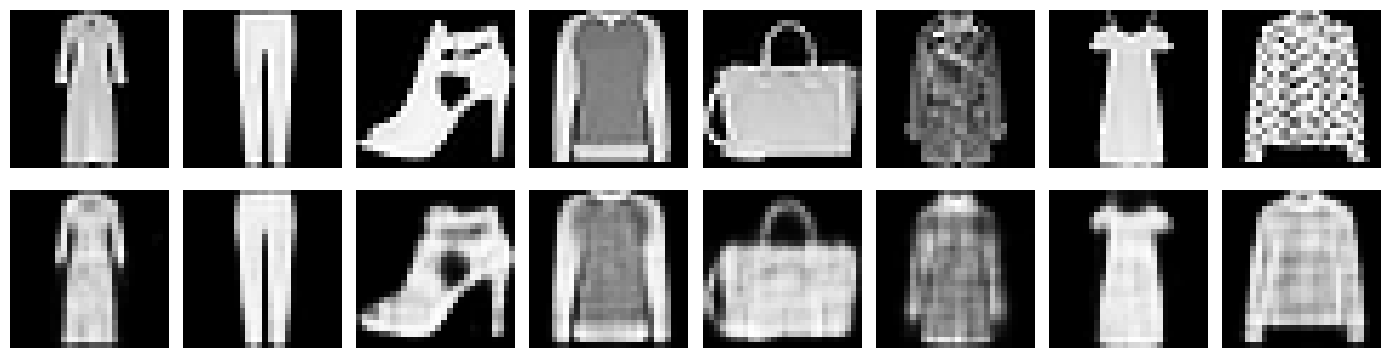

In [31]:
import matplotlib.pyplot as plt

images, _ = next(iter(test))
images = images[:8].to(device)
with torch.no_grad():
    xr, _, _ = model_sae(images)
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    ax[0, i].imshow(images[i,0].cpu(), cmap='gray'); ax[0, i].axis('off')
    ax[1, i].imshow(xr[i].cpu().reshape(28,28), cmap='gray'); ax[1, i].axis('off')
plt.tight_layout()
plt.show()

In [32]:
%%writefile src/sparse_ae.py
import torch, torch.nn as nn, torch.nn.functional as F, time
from src.data import get_loaders
from src.utils import set_seed, get_device

class SparseAE(nn.Module):
    def __init__(self, z_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, z_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def forward(self, x):
        h = self.encoder[1](self.encoder[0](x.flatten(1)))
        z = self.encoder[2](h)
        return self.decoder(z), z, h

def train_sparse_ae(epochs=30, lr=1e-3, batch_size=128, seed=42, lam=1e-3):
    set_seed(seed)
    device = get_device()
    train, val, test = get_loaders(batch_size, seed)
    model = SparseAE().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train': [], 'val': []}
    best_val, best_state, best_epoch = float('inf'), None, -1
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        for images, _ in train:
            images = images.to(device)
            optimizer.zero_grad()
            xr, _, h = model(images)
            loss = F.mse_loss(xr, images.flatten(1)) + lam * h.abs().mean()
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * images.size(0)
        history['train'].append(train_loss_sum / len(train.dataset))

        model.eval()
        val_loss_sum = 0
        with torch.no_grad():
            for images, _ in val:
                images = images.to(device)
                xr, _, _ = model(images)
                val_loss_sum += F.mse_loss(xr, images.flatten(1)).item() * images.size(0)
        history['val'].append(val_loss_sum / len(val.dataset))

        if history['val'][-1] < best_val:
            best_val = history['val'][-1]
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
            best_epoch = epoch + 1

        train_loss = history['train'][-1]
        val_loss = history['val'][-1]
        print(f'Epoch {epoch+1:02d} : train {train_loss:.5f} , val {val_loss:.5f}')

    model.load_state_dict(best_state)
    return model, history, (time.time() - start_time) / epochs, best_epoch, best_val

Writing src/sparse_ae.py


In [33]:
# Vanilla vs Sparse
import numpy as np

def hitung_sparsity(model, test_loader, device):
    model.eval()
    activation = []
    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            h = model.encoder[1](model.encoder[0](images.flatten(1)))
            activation.append(h.cpu())
    h_all = torch.cat(activation, dim=0)
    persen_nol = (h_all == 0).float().mean().item() * 100
    persentil_99 = torch.quantile(h_all, 0.99)
    persen_kecil = (h_all < 0.01 * persentil_99).float().mean().item() * 100
    return persen_nol, persen_kecil

nol_vanilla, kecil_vanilla = hitung_sparsity(model_ae, test, device)
nol_sparse, kecil_sparse = hitung_sparsity(model_sae, test, device)

print('VANILLA AE vs SPARSE AE (activation 256-d)')
print('='*25)
print(f'Vanilla: activation nol {nol_vanilla:.2f}% , activation kecil {kecil_vanilla:.2f}%')
print(f'Sparse : activation nol {nol_sparse:.2f}% , activation kecil {kecil_sparse:.2f}%')

VANILLA AE vs SPARSE AE (activation 256-d)
Vanilla: activation nol 44.09% , activation kecil 44.45%
Sparse : activation nol 59.20% , activation kecil 59.73%
